# CancerVerso · V2 — Datos listos para el modelo
**Pasos 1 y 3 del plan: inventario de los `volumen.npz` y dataset 2D para la U-Net.**

Qué hace, en orden:
1. Monta Drive y encuentra las 4 fuentes de datos (Isay + atajos de Paul, Christopher y Paloma).
2. **Inventario:** compara los `volumen.npz` que hay en Drive contra los checklists de cada parte y dice exactamente qué caso falta.
3. **Copia a disco local** en paralelo (y mide qué tan lento es leer de Drive archivo por archivo).
4. Tabla maestra de los 2,336 CTs.
5. **Validación** de cada `volumen.npz` (claves, tipos, tamaños, HTB% recalculado).
6. **Separación por paciente** 70/15/15 (un paciente nunca queda en dos grupos).
7. **Preprocesamiento 2D:** solo cortes con hígado, tamaño fijo 256×256, etiqueta 0/1/2.
8. **Empaquetado en shards** (pocos archivos grandes) y **balance de clases**.
9. Copia a Drive con **manifiesto** (linaje y huellas MD5).
10. **Benchmark de lectura:** archivos sueltos vs shards, desde Drive, disco local y RAM.
11. Vista rápida, cómo lo leerá la U-Net y bitácora de tiempos.

**Antes de empezar (una sola vez): atajos a las carpetas de tus compañeros**

Colab solo ve lo que está en *Mi unidad*. Las carpetas de tus compañeros están en *Compartidos conmigo*, así que hay que crear atajos:
1. En Drive, dentro de `Big data Zucco`, crea la carpeta **`companeros`**.
2. Ve a *Compartidos conmigo*. Ahí hay 3 carpetas llamadas `Big data Zucco` (dueños: Paul, Christopher y Paloma).
3. En cada una: clic derecho → *Organizar* → *Agregar acceso directo* → elige `Big data Zucco/companeros`.
4. Renombra los 3 atajos como **`parte1_paul`**, **`parte2_christopher`** y **`parte0_paloma`** (si los dejas con el mismo nombre, se confunden).

**Entorno:** CPU con RAM amplia es suficiente (así se corrió el 24 nov). Este notebook usa sobre todo CPU, RAM y disco; la G4 se usa en el paso 4. Si Colab se desconecta, vuelve a correr desde arriba: la copia se salta lo que ya está.

## 1. Drive, máquina y configuración

In [1]:
# ============================================================
# 1a. MONTAR DRIVE Y VER LA MÁQUINA
# ============================================================
from google.colab import drive
drive.mount("/content/drive")

import os
import glob
import time
import json
import shutil
import hashlib
import datetime
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import psutil

print("CPUs:", os.cpu_count())
print("RAM total:", round(psutil.virtual_memory().total / 1e9, 1), "GB")
print("Disco local libre:", round(shutil.disk_usage("/content").free / 1e9, 1), "GB")
os.system("nvidia-smi --query-gpu=name,memory.total --format=csv")

Mounted at /content/drive
CPUs: 8
RAM total: 54.8 GB
Disco local libre: 242.4 GB


32512

In [2]:
# ============================================================
# 1b. CONFIGURACIÓN: rutas y constantes en un solo lugar
# ============================================================
BASE = "/content/drive/MyDrive/Big data Zucco"
DIR_COMPANEROS = BASE + "/companeros"           # aquí van los 3 atajos
DIR_STATS = BASE + "/stats"                     # tablas CSV del proyecto
DIR_SALIDA_DRIVE = BASE + "/dataset_modelo/v2"  # v2 = ya sin los casos de píxel deformado (v1 fue la primera corrida)

LOCAL = "/content/cv_local"                     # disco local de Colab: rápido, pero se borra al desconectar
LOCAL_NPZ = LOCAL + "/npz"                      # copia local de los volumen.npz
LOCAL_SHARDS = LOCAL + "/shards"                # shards recién creados

TOTAL_ESPERADO = 2336        # CTs de hígado procesados por el equipo (sección 13 de la V1)
SEMILLA = 42                 # misma semilla = misma separación siempre
PCT_TRAIN = 0.70
PCT_VAL = 0.15               # el resto (15%) es prueba
LADO = 256                   # todos los cortes quedan de 256 x 256
CORTES_POR_SHARD = 2000      # ~2,000 cortes por archivo (~260 MB sin comprimir)
HILOS_COPIA = 16             # copias simultáneas desde Drive
N_BENCH = 100                # casos que se usan en el benchmark de archivos sueltos
MAX_RATIO_PIXEL = 1.5        # si el píxel es más de 1.5 veces más alto que ancho (o al revés), la imagen 2D sale deformada

# Lo que DEBE traer cada volumen.npz (así lo guarda la sección 8 de la V1)
CLAVES = ["ct", "tumor", "higado", "higado_ts", "espaciado_mm"]
# La ventana HU de tejido blando YA se aplicó al crear el volumen.npz (V1, sección 8):
# el CT viene como uint8 (0-255) que corresponde a -160..240 HU. Aquí solo se documenta.
VENTANA_HU = (-160, 240)

for carpeta in [LOCAL_NPZ, DIR_SALIDA_DRIVE]:
    os.makedirs(carpeta, exist_ok=True)
for split in ["train", "val", "test"]:
    os.makedirs(LOCAL_SHARDS + "/" + split, exist_ok=True)

# Bitácora: cuánto tarda cada etapa (sirve para el reporte "Cómo lo procesamos")
tiempos = []
medidas = []    # resultados del benchmark de lectura

def anotar(etapa, t0, detalle=""):
    segundos = round(time.time() - t0, 1)
    tiempos.append({"etapa": etapa, "segundos": segundos, "detalle": detalle})
    print("Tiempo de '" + etapa + "':", segundos, "s", detalle)

# --- Fuentes de datos: la carpeta de Isay + cada atajo de compañero ---
fuentes = {"isay": BASE}
for carpeta in sorted(glob.glob(DIR_COMPANEROS + "/*")):
    if os.path.isdir(carpeta + "/procesados/higado"):
        fuentes[os.path.basename(carpeta)] = carpeta
for nombre, ruta in fuentes.items():
    print(nombre, "->", ruta)
if len(fuentes) < 4:
    print("\nAVISO: se esperaban 4 fuentes y hay", len(fuentes), ". Revisa los atajos en", DIR_COMPANEROS)

isay -> /content/drive/MyDrive/Big data Zucco
parte0_paloma -> /content/drive/MyDrive/Big data Zucco/companeros/parte0_paloma
parte1_paul -> /content/drive/MyDrive/Big data Zucco/companeros/parte1_paul
parte2_christopher -> /content/drive/MyDrive/Big data Zucco/companeros/parte2_christopher


## 2. Inventario (paso 1)
Se compara lo que **dice** cada checklist (casos con estado `ok`) contra lo que **hay** en Drive (`procesados/higado/CV_XXXXXXXX/volumen.npz`).

- **Faltan:** el checklist dice `ok`, pero no está el archivo.
- **Duplicados:** el mismo caso en dos fuentes. Pasa con los 173 casos que Paloma repitió de la parte 0 (sirvieron como prueba de reproducibilidad). Se usa la copia de Isay.

In [3]:
# ============================================================
# 2. INVENTARIO: lo que dicen los checklists vs. lo que hay en Drive
# ============================================================
t0 = time.time()

# 2a. Lo que HAY: recorrer las carpetas de cada fuente
filas = []
for fuente, raiz in fuentes.items():
    carpeta = raiz + "/procesados/higado"
    for caso in sorted(os.listdir(carpeta)):
        ruta = carpeta + "/" + caso + "/volumen.npz"
        if caso.startswith("CV_") and os.path.exists(ruta):
            filas.append({"caso": caso, "fuente": fuente, "ruta": ruta, "mb": round(os.path.getsize(ruta) / 1e6, 3)})
encontrados = pd.DataFrame(filas)

# 2b. Lo que DEBERÍA haber: casos "ok" en el checklist de cada fuente
listas = []
for fuente, raiz in fuentes.items():
    for ruta in glob.glob(raiz + "/stats/checklist_higado_parte*.csv"):
        chk = pd.read_csv(ruta).drop_duplicates("caso", keep="last")    # último estado de cada caso
        chk = chk[chk["estado"] == "ok"]
        listas.append(pd.DataFrame({"caso": chk["caso"], "fuente": fuente}))
esperados = pd.concat(listas, ignore_index=True)

# 2c. Comparar fuente por fuente
resumen = []
faltantes = []
for fuente in fuentes:
    esp = set(esperados[esperados["fuente"] == fuente]["caso"])
    hay = set(encontrados[encontrados["fuente"] == fuente]["caso"])
    faltan = sorted(esp - hay)
    faltantes += [{"caso": c, "fuente": fuente} for c in faltan]
    resumen.append({"fuente": fuente, "en_checklist": len(esp), "npz_en_drive": len(hay),
                    "faltan": len(faltan), "sin_checklist": len(hay - esp),
                    "gb": round(encontrados[encontrados["fuente"] == fuente]["mb"].sum() / 1000, 2)})
resumen = pd.DataFrame(resumen)
print(resumen.to_string(index=False))

# 2d. Una sola copia por caso (prioridad: la de Isay)
encontrados["prioridad"] = (encontrados["fuente"] != "isay").astype(int)
canon = encontrados.sort_values(["prioridad", "fuente"]).drop_duplicates("caso").drop(columns="prioridad")
canon = canon[canon["caso"].isin(esperados["caso"])].sort_values("caso").reset_index(drop=True)
n_dup = len(encontrados) - encontrados["caso"].nunique()

print("\nCasos repetidos entre fuentes:", n_dup, "(se usa la copia de Isay)")
print("Casos únicos en los checklists:", esperados["caso"].nunique(), "(meta:", TOTAL_ESPERADO, ")")
print("Casos únicos con volumen.npz:", len(canon), "de", TOTAL_ESPERADO, "|", round(canon["mb"].sum() / 1000, 2), "GB")
if len(faltantes) > 0:
    print("\nFALTAN", len(faltantes), "archivos:")
    print(pd.DataFrame(faltantes).to_string(index=False))
else:
    print("No falta ningún archivo.")

canon.to_csv(DIR_STATS + "/inventario_npz.csv", index=False)
pd.DataFrame(faltantes, columns=["caso", "fuente"]).to_csv(DIR_STATS + "/inventario_faltantes.csv", index=False)
anotar("inventario en Drive", t0, str(len(encontrados)) + " archivos revisados")

            fuente  en_checklist  npz_en_drive  faltan  sin_checklist   gb
              isay          1909          1909       0              0 4.92
     parte0_paloma           200           200       0              0 0.52
       parte1_paul           200           200       0              0 0.51
parte2_christopher           200           200       0              0 0.51

Casos repetidos entre fuentes: 173 (se usa la copia de Isay)
Casos únicos en los checklists: 2336 (meta: 2336 )
Casos únicos con volumen.npz: 2336 de 2336 | 6.0 GB
No falta ningún archivo.
Tiempo de 'inventario en Drive': 143.7 s 2509 archivos revisados


## 3. Copia a disco local
**Drive es la bodega y el disco local es la mesa de trabajo.** Leer miles de archivos chicos desde Drive es lento porque cada archivo es una petición por red.

Primero medimos esa lentitud con 100 casos, uno por uno (1 hilo). Después copiamos todo con **16 copias al mismo tiempo**: mientras una espera a la red, las otras avanzan.

In [4]:
# ============================================================
# 3. BENCHMARK (Drive, archivo por archivo) Y COPIA PARALELA A DISCO LOCAL
# ============================================================
def contar_cortes_con_higado(ruta):
    # Lee de verdad un volumen.npz: el CT y el hígado, y se queda con los cortes que tienen hígado
    v = np.load(ruta)
    con_higado = v["higado"].any(axis=(1, 2))
    cortes = v["ct"][con_higado]
    return len(cortes)

# 3a. Benchmark: 100 casos leídos desde Drive, de uno en uno
muestra = canon.sample(N_BENCH, random_state=SEMILLA)
t0 = time.time()
n_cortes = 0
for ruta in muestra["ruta"]:
    n_cortes += contar_cortes_con_higado(ruta)
seg = time.time() - t0
medidas.append({"prueba": "Sueltos desde Drive (1 hilo)", "cortes": n_cortes, "segundos": round(seg, 2),
                "mb": round(muestra["mb"].sum(), 1)})
print("Drive, 1 hilo:", N_BENCH, "casos en", round(seg, 1), "s ->", round(n_cortes / seg), "cortes/s")

# 3b. Copia paralela (se salta lo que ya está copiado con el mismo tamaño)
def copiar(caso, ruta):
    destino = LOCAL_NPZ + "/" + caso + ".npz"
    if os.path.exists(destino) and os.path.getsize(destino) == os.path.getsize(ruta):
        return 0
    shutil.copy(ruta, destino + ".tmp")       # se copia con otro nombre y luego se renombra:
    os.rename(destino + ".tmp", destino)      # así nunca queda un archivo a medias con el nombre bueno
    return 1

t0 = time.time()
with ThreadPoolExecutor(HILOS_COPIA) as pool:
    resultados = list(pool.map(copiar, canon["caso"], canon["ruta"]))
seg = time.time() - t0
gb = canon["mb"].sum() / 1000
print("Copiados:", sum(resultados), "| ya estaban:", len(resultados) - sum(resultados))
print("Velocidad:", round(1000 * gb / seg, 1), "MB/s |", round(len(canon) / seg, 1), "archivos/s")
anotar("copia Drive -> disco local", t0, str(HILOS_COPIA) + " hilos, " + str(round(gb, 2)) + " GB")
canon["ruta_local"] = LOCAL_NPZ + "/" + canon["caso"] + ".npz"

Drive, 1 hilo: 100 casos en 93.5 s -> 85 cortes/s
Copiados: 2336 | ya estaban: 0
Velocidad: 70.7 MB/s | 27.5 archivos/s
Tiempo de 'copia Drive -> disco local': 84.9 s 16 hilos, 6.0 GB


## 4. Tabla maestra de casos
Une las tablas `casos_higado_parte*.csv` de las 4 fuentes. Cada caso se toma **de la misma fuente** que su `volumen.npz`, para que métricas y volumen vengan de la misma corrida.

In [5]:
# ============================================================
# 4. TABLA MAESTRA: una fila por CT, con su paciente y sus métricas
# ============================================================
listas = []
for fuente, raiz in fuentes.items():
    for ruta in glob.glob(raiz + "/stats/casos_higado_parte*.csv"):
        t = pd.read_csv(ruta).drop_duplicates("caso", keep="last")
        t["fuente"] = fuente
        listas.append(t)
todas = pd.concat(listas, ignore_index=True)

columnas = ["caso", "fuente", "paciente", "fecha", "sexo", "edad", "fase",
            "vol_tumor_cm3", "vol_higado_cm3", "htb_pct", "n_lesiones", "n_cortes", "ts_rapido"]
tabla = canon[["caso", "fuente", "ruta_local", "mb"]].merge(todas[columnas], on=["caso", "fuente"], how="left")

sin_metricas = tabla["paciente"].isna().sum()
print(len(tabla), "CTs |", tabla["paciente"].nunique(), "pacientes | sin fila de métricas:", sin_metricas)
if tabla["ts_rapido"].any():
    print("AVISO:", int(tabla["ts_rapido"].sum()), "casos se procesaron con --fast (provisionales)")
tabla.head()

2336 CTs | 1319 pacientes | sin fila de métricas: 0


,caso,fuente,ruta_local,mb,paciente,fecha,sexo,edad,fase,vol_tumor_cm3,vol_higado_cm3,htb_pct,n_lesiones,n_cortes,ts_rapido
0,CV_00000012,isay,/content/cv_local/npz/CV_00000012.npz,2.464,N10C8D1FT10YYTYJ,2021-10-27,F,53.0,arterial_late,14.52,1597.3,0.91,39,96,False
1,CV_00000024,parte2_christopher,/content/cv_local/npz/CV_00000024.npz,2.270,S25QUR17CQCWWVN8,2023-05-27,M,43.0,venous,39.53,2636.0,1.50,30,96,False
2,CV_00000035,isay,/content/cv_local/npz/CV_00000035.npz,2.556,2QYIU888NZJW94OQ,2018-03-30,F,71.0,portal_venous,3.49,1233.9,0.28,7,96,False
3,CV_00000050,isay,/content/cv_local/npz/CV_00000050.npz,3.117,E328DS06YG4YVORE,2018-09-03,F,40.0,portal_venous,101.94,1376.7,7.40,26,96,False
4,CV_00000052,isay,/content/cv_local/npz/CV_00000052.npz,3.275,QTNSQU22DUC31MI8,2023-03-26,F,66.0,arterial_early,94.93,1366.4,6.95,24,96,False


## 5. Validación de cada `volumen.npz`
Antes de transformar, se revisa que cada archivo esté sano:
- Abre sin error y trae las 5 claves (`ct`, `tumor`, `higado`, `higado_ts`, `espaciado_mm`).
- `ct` es `uint8` y las 4 matrices tienen el mismo tamaño.
- El tumor está dentro del hígado (debe ser así, porque `higado` = TotalSegmentator ∪ tumor).
- **HTB% recalculado** con el volumen reducido vs. el HTB% original (resolución completa). Deben parecerse; una diferencia grande indica un archivo raro.
- **Píxel cuadrado.** Algunas series se adquirieron en otro plano con cortes gruesos: al verlas en axial, cada píxel mide, por ejemplo, 10.4 mm de alto y 1.3 mm de ancho, y la imagen queda aplastada (ej. `CV_00001181`, 22×256 px). Si el píxel es más de `MAX_RATIO_PIXEL` (1.5) veces más alto que ancho, o al revés, el caso **sale del dataset 2D** y queda anotado en `excluidos_anisotropia.csv`. Su HTB% de la V1 sigue siendo válido porque se midió a resolución completa; solo no se usa para entrenar la U-Net.

In [6]:
# ============================================================
# 5. VALIDAR CADA volumen.npz
# ============================================================
t0 = time.time()
filas = []
for _, fila in tabla.iterrows():
    r = {"caso": fila["caso"], "estado": "ok", "detalle": ""}
    try:
        v = np.load(fila["ruta_local"])
        faltan = [c for c in CLAVES if c not in v.files]
        if faltan:
            raise ValueError("faltan claves " + str(faltan))
        ct, tumor, higado = v["ct"], v["tumor"], v["higado"]
        if ct.dtype != np.uint8:
            raise ValueError("ct no es uint8 sino " + str(ct.dtype))
        if not (ct.shape == tumor.shape == higado.shape == v["higado_ts"].shape):
            raise ValueError("tamaños distintos")
        r["cortes"], r["alto"], r["ancho"] = ct.shape
        r["cortes_con_higado"] = int(higado.any(axis=(1, 2)).sum())
        r["tumor_fuera_higado_px"] = int((tumor & ~higado).sum())
        r["htb_npz"] = round(100 * tumor.sum() / max(higado.sum(), 1), 2)
        esp = v["espaciado_mm"]                          # mm por [corte, fila, columna]
        r["mm_fila"], r["mm_columna"] = round(float(esp[1]), 3), round(float(esp[2]), 3)
        r["ratio_pixel"] = round(max(esp[1], esp[2]) / min(esp[1], esp[2]), 2)   # 1.0 = píxel cuadrado
    except Exception as e:
        r["estado"] = "error"
        r["detalle"] = str(e)[:200]
    filas.append(r)

validacion = pd.DataFrame(filas).merge(tabla[["caso", "htb_pct"]], on="caso")
validacion["dif_htb"] = (validacion["htb_npz"] - validacion["htb_pct"]).abs()
validacion.to_csv(DIR_STATS + "/validacion_npz.csv", index=False)

malos = validacion[validacion["estado"] != "ok"]
print("Archivos con error:", len(malos))
if len(malos) > 0:
    print(malos[["caso", "detalle"]].to_string(index=False))
print("Casos con tumor fuera del hígado:", int((validacion["tumor_fuera_higado_px"] > 0).sum()))
print("Diferencia de HTB% (reducido vs. original): mediana", round(validacion["dif_htb"].median(), 2),
      "| p95", round(validacion["dif_htb"].quantile(0.95), 2), "| máx.", round(validacion["dif_htb"].max(), 2))
print("Tamaños de corte (alto x ancho) más comunes:")
print(validacion.groupby(["alto", "ancho"]).size().sort_values(ascending=False).head())

# Píxel deformado: el caso está sano, pero su imagen 2D no sirve para entrenar
deformados = validacion[(validacion["estado"] == "ok") & (validacion["ratio_pixel"] > MAX_RATIO_PIXEL)]
deformados = deformados.merge(tabla[["caso", "fuente", "paciente"]], on="caso")
deformados = deformados[["caso", "fuente", "paciente", "alto", "ancho", "mm_fila", "mm_columna", "ratio_pixel", "htb_pct"]]
deformados.sort_values("ratio_pixel", ascending=False).to_csv(DIR_STATS + "/excluidos_anisotropia.csv", index=False)
print("\nCasos con píxel deformado (ratio >", MAX_RATIO_PIXEL, "):", len(deformados), "-> salen del dataset 2D")
print("Ratio de píxel: mediana", validacion["ratio_pixel"].median(), "| máx.", validacion["ratio_pixel"].max())
if len(deformados) > 0:
    print(deformados.sort_values("ratio_pixel", ascending=False).head(10).to_string(index=False))

# Siguen adelante solo los casos sanos y con píxel (casi) cuadrado
buenos = validacion[(validacion["estado"] == "ok") & (validacion["ratio_pixel"] <= MAX_RATIO_PIXEL)]["caso"]
tabla = tabla[tabla["caso"].isin(buenos)].reset_index(drop=True)
anotar("validación de npz", t0, str(len(tabla)) + " casos sanos y con píxel cuadrado")

Archivos con error: 0
Casos con tumor fuera del hígado: 0
Diferencia de HTB% (reducido vs. original): mediana 0.07 | p95 0.56 | máx. 1.53
Tamaños de corte (alto x ancho) más comunes:
alto  ancho
256   256      2218
46    256         5
256   68          5
44    256         4
60    256         4
dtype: int64

Casos con píxel deformado (ratio > 1.5 ): 72 -> salen del dataset 2D
Ratio de píxel: mediana 1.0 | máx. 7.860000133514404
       caso             fuente         paciente  alto  ancho  mm_fila  mm_columna  ratio_pixel  htb_pct
CV_00001181               isay 57JESWAFOGWJFAKN    22    256   10.371       1.320         7.86     0.77
CV_00023030               isay J8VU7ZOMF2JRB60K    23    256    9.551       1.238         7.71     0.00
CV_00018034               isay 57JESWAFOGWJFAKN    24    256    9.854       1.285         7.67     0.64
CV_00021434        parte1_paul Y3E8CXNQOTK7LYNB    32    256   10.000       1.340         7.46     1.87
CV_00016034               isay 57JESWAFOGWJFAKN  

## 6. Separación por paciente (70 / 15 / 15)
Un paciente puede tener varios CTs (seguimiento y fases). Si sus CTs quedaran en entrenamiento **y** en prueba, el modelo "ya habría visto" a ese paciente y la calificación saldría inflada (fuga de datos).

Por eso se reparten **pacientes**, no CTs. Con la semilla fija la separación siempre sale igual y queda guardada en `split_pacientes.csv`.

In [7]:
# ============================================================
# 6. SEPARACIÓN POR PACIENTE
# ============================================================
pacientes = np.array(sorted(tabla["paciente"].unique()))
rng = np.random.default_rng(SEMILLA)
rng.shuffle(pacientes)

n = len(pacientes)
n_train = int(round(n * PCT_TRAIN))
n_val = int(round(n * PCT_VAL))
grupo = {}
for p in pacientes[:n_train]:
    grupo[p] = "train"
for p in pacientes[n_train:n_train + n_val]:
    grupo[p] = "val"
for p in pacientes[n_train + n_val:]:
    grupo[p] = "test"
tabla["split"] = tabla["paciente"].map(grupo)

# Comprobación: ningún paciente en dos grupos
assert tabla.groupby("paciente")["split"].nunique().max() == 1, "Hay un paciente en dos grupos"

resumen_split = tabla.groupby("split").agg(
    pacientes=("paciente", "nunique"), cts=("caso", "count"),
    htb_media=("htb_pct", "mean"), htb_mediana=("htb_pct", "median"),
    vol_tumor_mediana_cm3=("vol_tumor_cm3", "median"),
).round(2).loc[["train", "val", "test"]]
resumen_split["pct_cts"] = (100 * resumen_split["cts"] / resumen_split["cts"].sum()).round(1)
print(resumen_split.to_string())

tabla[["caso", "paciente", "split", "fuente"]].to_csv(DIR_STATS + "/split_pacientes.csv", index=False)

       pacientes   cts  htb_media  htb_mediana  vol_tumor_mediana_cm3  pct_cts
split                                                                         
train        904  1582       7.05         1.69                  26.75     69.9
val          194   336       7.45         2.28                  36.29     14.8
test         193   346       6.08         1.64                  23.18     15.3


## 7. Preprocesamiento 2D y shards
Para cada CT:
1. **Solo cortes con hígado.** Los cortes sin hígado no enseñan nada para esta tarea y harían el dataset más grande.
2. **Tamaño fijo 256×256.** Casi todos ya miden eso; los que no, se rellenan con ceros (centrados).
3. **Etiqueta por píxel:** 0 = fondo, 1 = hígado sin tumor, 2 = tumor.
4. **El CT se guarda como `uint8` (0–255).** La normalización a 0–1 se hace al cargar cada lote (`/ 255`). Guardar en `float32` ocuparía **4 veces más** disco y RAM sin ganar información.

**Shards:** en lugar de miles de archivos chicos, se juntan unos 2,000 cortes por archivo. Los casos se barajan antes, para que cada shard mezcle pacientes. Se guardan **sin comprimir** (`np.savez`) porque leerlos es casi gratis; el costo de comprimir se pagaría en cada época de entrenamiento.

In [8]:
# ============================================================
# 7. PREPROCESAR Y EMPAQUETAR EN SHARDS
# ============================================================
def a_cuadrado(arr):
    # Rellena con ceros (o recorta) cada corte para que quede de LADO x LADO, centrado
    z, alto, ancho = arr.shape
    salida = np.zeros((z, LADO, LADO), dtype=arr.dtype)
    a, b = min(alto, LADO), min(ancho, LADO)
    y0, x0 = (LADO - a) // 2, (LADO - b) // 2
    salida[:, y0:y0 + a, x0:x0 + b] = arr[:, :a, :b]
    return salida

def preparar_caso(ruta):
    # Devuelve (imagenes uint8, etiquetas uint8, número de corte original) solo de los cortes con hígado
    v = np.load(ruta)
    higado = v["higado"]                         # se lee una sola vez (cada lectura descomprime)
    con_higado = higado.any(axis=(1, 2))
    ct = v["ct"][con_higado]
    etiqueta = np.zeros(ct.shape, dtype=np.uint8)
    etiqueta[higado[con_higado]] = 1            # hígado
    etiqueta[v["tumor"][con_higado]] = 2        # tumor (encima del hígado)
    return a_cuadrado(ct), a_cuadrado(etiqueta), np.where(con_higado)[0]

def guardar_shard(split, numero, imagenes, etiquetas):
    ruta = LOCAL_SHARDS + "/" + split + "/shard_" + str(numero).zfill(3) + ".npz"
    np.savez(ruta, img=np.concatenate(imagenes), lbl=np.concatenate(etiquetas))
    return ruta

# Si esta celda ya corrió antes en esta sesión, se borran los shards LOCALES viejos para no mezclarlos
shutil.rmtree(LOCAL_SHARDS, ignore_errors=True)
for split in ["train", "val", "test"]:
    os.makedirs(LOCAL_SHARDS + "/" + split, exist_ok=True)

t0 = time.time()
indice = []                                      # una fila por corte: de qué caso viene y dónde quedó
for split in ["train", "val", "test"]:
    casos_split = tabla[tabla["split"] == split].sample(frac=1, random_state=SEMILLA)   # barajar casos
    imagenes, etiquetas, en_buffer, numero = [], [], 0, 0
    for _, fila in casos_split.iterrows():
        img, lbl, cortes = preparar_caso(fila["ruta_local"])
        for k in range(len(cortes)):
            indice.append({"split": split, "shard": numero, "fila": en_buffer + k, "caso": fila["caso"],
                           "paciente": fila["paciente"], "corte_original": int(cortes[k]),
                           "px_higado": int((lbl[k] == 1).sum()), "px_tumor": int((lbl[k] == 2).sum())})
        imagenes.append(img)
        etiquetas.append(lbl)
        en_buffer += len(img)
        if en_buffer >= CORTES_POR_SHARD:            # el buffer se llenó: guardar un shard
            guardar_shard(split, numero, imagenes, etiquetas)
            imagenes, etiquetas, en_buffer, numero = [], [], 0, numero + 1
    if en_buffer > 0:                                 # lo que sobró va a un último shard
        guardar_shard(split, numero, imagenes, etiquetas)
    print(split, "listo")

indice = pd.DataFrame(indice)
indice["tiene_tumor"] = indice["px_tumor"] > 0
indice.to_csv(LOCAL_SHARDS + "/indice_cortes.csv", index=False)

archivos_shard = sorted(glob.glob(LOCAL_SHARDS + "/*/shard_*.npz"))
gb_shards = sum(os.path.getsize(r) for r in archivos_shard) / 1e9
print(len(indice), "cortes en", len(archivos_shard), "shards |", round(gb_shards, 2), "GB")
anotar("preprocesamiento + shards", t0, str(len(indice)) + " cortes")

train listo
val listo
test listo
180238 cortes en 90 shards | 23.62 GB
Tiempo de 'preprocesamiento + shards': 226.3 s 180238 cortes


## 8. Balance de clases
El tumor ocupa muy pocos píxeles comparado con el fondo y el hígado. Un modelo "flojo" que nunca pinte tumor tendría una exactitud altísima y no serviría. Esta tabla deja documentado el desbalance y la decisión:

- **No se tiran cortes sin tumor:** el modelo también debe aprender a decir "aquí no hay tumor".
- **Pérdida Dice + entropía cruzada** en el paso 4 (Dice no se deja engañar por el fondo).
- Los pesos inversos a la frecuencia quedan calculados por si se necesitan.

In [9]:
# ============================================================
# 8. BALANCE DE CLASES POR GRUPO
# ============================================================
px_corte = LADO * LADO
balance = indice.groupby("split").agg(
    cortes=("caso", "count"), cortes_con_tumor=("tiene_tumor", "sum"),
    px_higado=("px_higado", "sum"), px_tumor=("px_tumor", "sum"),
).loc[["train", "val", "test"]]
balance["px_fondo"] = balance["cortes"] * px_corte - balance["px_higado"] - balance["px_tumor"]
total_px = balance["cortes"] * px_corte
balance["pct_cortes_con_tumor"] = (100 * balance["cortes_con_tumor"] / balance["cortes"]).round(1)
balance["pct_fondo"] = (100 * balance["px_fondo"] / total_px).round(2)
balance["pct_higado"] = (100 * balance["px_higado"] / total_px).round(2)
balance["pct_tumor"] = (100 * balance["px_tumor"] / total_px).round(3)
print(balance[["cortes", "pct_cortes_con_tumor", "pct_fondo", "pct_higado", "pct_tumor"]].to_string())

# Pesos inversos a la frecuencia (calculados solo con train, normalizados para que el fondo valga 1)
tr = balance.loc["train"]
frecuencias = np.array([tr["px_fondo"], tr["px_higado"], tr["px_tumor"]], dtype=float)
pesos = (1 / frecuencias) / (1 / frecuencias[0])
print("\nPesos sugeridos [fondo, hígado, tumor]:", pesos.round(1).tolist())
balance.to_csv(DIR_STATS + "/balance_clases.csv")

       cortes  pct_cortes_con_tumor  pct_fondo  pct_higado  pct_tumor
split                                                                
train  126199                  48.4      92.82        6.54      0.635
val     26671                  52.8      92.55        6.77      0.679
test    27368                  44.9      93.15        6.33      0.518

Pesos sugeridos [fondo, hígado, tumor]: [1.0, 14.2, 146.1]


## 9. Copia a Drive con manifiesto
El **manifiesto** (`manifest.json`) es el linaje del dataset: de dónde salió, con qué parámetros y una huella MD5 de cada shard. Si un archivo se corrompe o alguien lo cambia, la huella ya no coincide.

In [10]:
# ============================================================
# 9. MANIFIESTO Y COPIA DE LOS SHARDS A DRIVE
# ============================================================
def md5(ruta):
    h = hashlib.md5()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(bloque)
    return h.hexdigest()

t0 = time.time()
lista_archivos = []
for ruta in archivos_shard:
    lista_archivos.append({"archivo": os.path.relpath(ruta, LOCAL_SHARDS),
                           "mb": round(os.path.getsize(ruta) / 1e6, 1), "md5": md5(ruta)})

manifest = {
    "nombre": "CancerVerso dataset 2D hígado v2",
    "creado": datetime.datetime.now().isoformat(timespec="seconds"),
    "origen": "BodyMaps/CancerVerse (Hugging Face) -> volumen.npz de la V1 (TotalSegmentator + máscara liver_lesion)",
    "fuentes": {f: int((tabla["fuente"] == f).sum()) for f in fuentes},
    "ventana_hu": list(VENTANA_HU),
    "formato": {"img": "uint8 [N,256,256], 0-255 (dividir entre 255 al cargar)",
                "lbl": "uint8 [N,256,256], 0 fondo / 1 hígado / 2 tumor"},
    "semilla": SEMILLA,
    "excluidos": {"archivo_con_error": int((validacion["estado"] != "ok").sum()),
                  "pixel_deformado": int(len(deformados)),
                  "criterio_pixel": "max(mm_fila, mm_columna) / min(...) > " + str(MAX_RATIO_PIXEL)},
    "separacion": "por paciente 70/15/15",
    "cts": {s: int((tabla["split"] == s).sum()) for s in ["train", "val", "test"]},
    "pacientes": {s: int(tabla[tabla["split"] == s]["paciente"].nunique()) for s in ["train", "val", "test"]},
    "cortes": {s: int((indice["split"] == s).sum()) for s in ["train", "val", "test"]},
    "archivos": lista_archivos,
}
with open(LOCAL_SHARDS + "/manifest.json", "w") as f:
    json.dump(manifest, f, indent=2, ensure_ascii=False)

shutil.copytree(LOCAL_SHARDS, DIR_SALIDA_DRIVE, dirs_exist_ok=True)
anotar("md5 + copia de shards a Drive", t0, str(round(gb_shards, 2)) + " GB")
print("Listo en", DIR_SALIDA_DRIVE)

Tiempo de 'md5 + copia de shards a Drive': 272.4 s 23.62 GB
Listo en /content/drive/MyDrive/Big data Zucco/dataset_modelo/v2


## 10. Benchmark de lectura
Misma pregunta en todos los casos: **¿cuántos cortes con hígado por segundo puedo darle al modelo?**

| Prueba | Qué mide |
|---|---|
| Sueltos desde Drive | 100 `volumen.npz` leídos de uno en uno desde Drive (medido en la sección 3, antes de copiar) |
| Sueltos desde disco local | los mismos 100 casos, desde `/content` |
| Shards desde Drive | 2 shards de train leídos desde Drive |
| Shards desde disco local | los mismos 2 shards desde `/content` |
| RAM | los cortes ya cargados: solo convertir a 0–1 en lotes de 256 |

**Ojo:** los shards se acaban de escribir en Drive y Colab puede tenerlos en caché, así que "Shards desde Drive" puede salir optimista. Para una medida estricta, corre esta sección en una sesión nueva.

                      prueba  cortes  segundos    mb  cortes_por_s  veces_vs_drive_sueltos
Sueltos desde Drive (1 hilo)    7936    93.540 250.5          85.0                     1.0
   Sueltos desde disco local    7936     6.040 250.5        1314.0                    15.5
          Shards desde Drive    4100     2.460 537.4        1667.0                    19.6
    Shards desde disco local    4100     0.980 537.4        4184.0                    49.2
                         RAM    4100     0.698 268.7        5874.0                    69.1


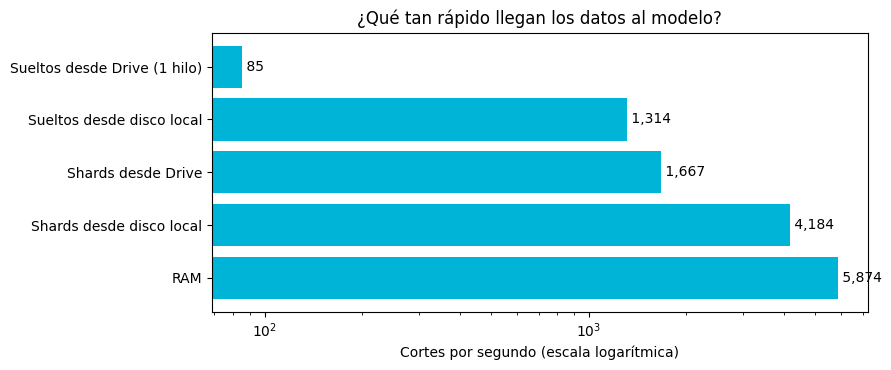

In [11]:
# ============================================================
# 10. BENCHMARK: archivos sueltos vs. shards, desde Drive, disco local y RAM
# ============================================================
# 10b. Sueltos desde disco local (mismos 100 casos de la sección 3)
t0 = time.time()
n_cortes = 0
for caso in muestra["caso"]:
    n_cortes += contar_cortes_con_higado(LOCAL_NPZ + "/" + caso + ".npz")
medidas.append({"prueba": "Sueltos desde disco local", "cortes": n_cortes, "segundos": round(time.time() - t0, 2),
                "mb": round(muestra["mb"].sum(), 1)})

def leer_shards(rutas):
    imagenes, etiquetas = [], []
    for ruta in rutas:
        s = np.load(ruta)
        imagenes.append(s["img"])
        etiquetas.append(s["lbl"])
    return imagenes, etiquetas

shards_prueba = sorted(glob.glob(LOCAL_SHARDS + "/train/shard_*.npz"))[:2]
mb_prueba = sum(os.path.getsize(r) for r in shards_prueba) / 1e6

# 10c. Shards desde Drive
t0 = time.time()
imgs, _ = leer_shards([DIR_SALIDA_DRIVE + "/train/" + os.path.basename(r) for r in shards_prueba])
medidas.append({"prueba": "Shards desde Drive", "cortes": sum(len(x) for x in imgs),
                "segundos": round(time.time() - t0, 2), "mb": round(mb_prueba, 1)})

# 10d. Shards desde disco local
t0 = time.time()
imgs, _ = leer_shards(shards_prueba)
medidas.append({"prueba": "Shards desde disco local", "cortes": sum(len(x) for x in imgs),
                "segundos": round(time.time() - t0, 2), "mb": round(mb_prueba, 1)})

# 10e. Desde RAM: los cortes ya están cargados; solo se normalizan a 0-1 por lotes
en_ram = np.concatenate(imgs)
t0 = time.time()
for i in range(0, len(en_ram), 256):
    lote = en_ram[i:i + 256].astype(np.float32) / 255
medidas.append({"prueba": "RAM", "cortes": len(en_ram), "segundos": round(time.time() - t0, 3),
                "mb": round(en_ram.nbytes / 1e6, 1)})

bench = pd.DataFrame(medidas)
bench["cortes_por_s"] = (bench["cortes"] / bench["segundos"].clip(lower=0.001)).round(0)
bench["veces_vs_drive_sueltos"] = (bench["cortes_por_s"] / bench["cortes_por_s"].iloc[0]).round(1)
print(bench.to_string(index=False))
bench.to_csv(DIR_STATS + "/benchmark_lectura.csv", index=False)

import matplotlib.pyplot as plt
fig, eje = plt.subplots(figsize=(9, 3.8))
eje.barh(bench["prueba"], bench["cortes_por_s"], color="#00b4d8")
eje.set_xscale("log")
eje.set_xlabel("Cortes por segundo (escala logarítmica)")
eje.set_title("¿Qué tan rápido llegan los datos al modelo?")
eje.invert_yaxis()
for i, valor in enumerate(bench["cortes_por_s"]):
    eje.text(valor, i, " " + format(int(valor), ","), va="center")
plt.tight_layout()
fig.savefig(DIR_STATS + "/benchmark_lectura.png", dpi=130)
plt.show()

## 11. Vista rápida: ¿las etiquetas caen donde deben?

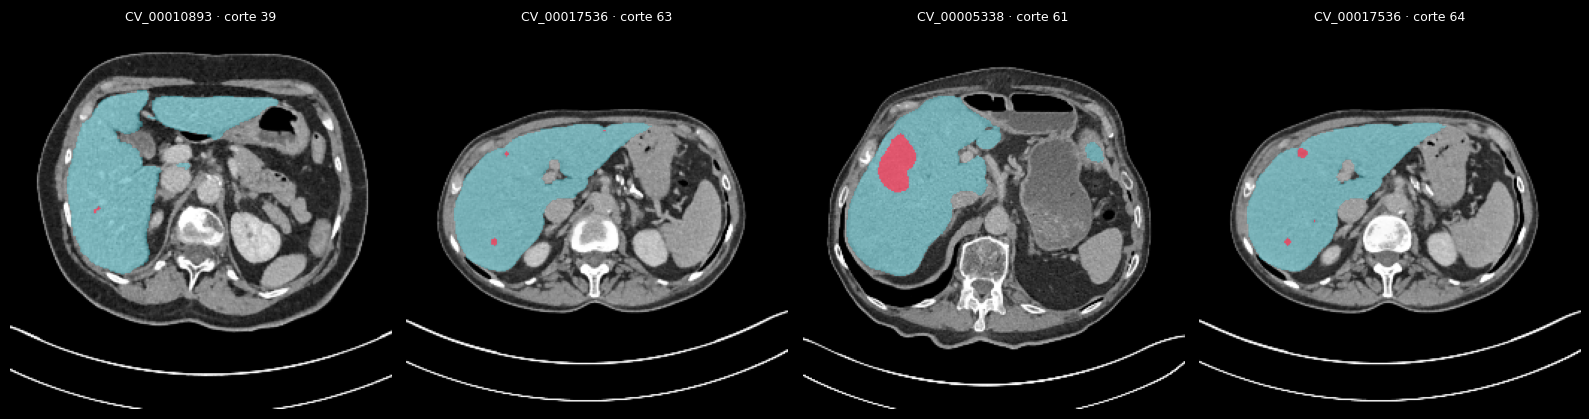

In [12]:
# ============================================================
# 11. VISTA RÁPIDA DE 4 CORTES CON TUMOR (del primer shard de train)
# ============================================================
s = np.load(LOCAL_SHARDS + "/train/shard_000.npz")
filas_tumor = indice[(indice["split"] == "train") & (indice["shard"] == 0) & indice["tiene_tumor"]]
elegidas = filas_tumor.sample(4, random_state=SEMILLA)

fig, ejes = plt.subplots(1, 4, figsize=(16, 4.4), facecolor="black")
for eje, (_, f) in zip(ejes, elegidas.iterrows()):
    img, lbl = s["img"][f["fila"]], s["lbl"][f["fila"]]
    capa = np.zeros((LADO, LADO, 4))
    capa[lbl == 1] = (0.0, 0.9, 1.0, 0.25)       # hígado en cian
    capa[lbl == 2] = (1.0, 0.23, 0.36, 0.7)      # tumor en rojo
    eje.imshow(img, cmap="gray", vmin=0, vmax=255)
    eje.imshow(capa)
    eje.set_title(f["caso"] + " · corte " + str(f["corte_original"]), color="white", fontsize=9)
    eje.axis("off")
plt.tight_layout()
plt.show()

## 12. Cómo lo leerá la U-Net (paso 4)
Un `Dataset` de PyTorch mínimo: carga los shards de un grupo a la RAM una sola vez y entrega cada corte ya normalizado a 0–1. Con los datos en RAM, la GPU no se queda esperando al disco.

In [13]:
# ============================================================
# 12. DATASET DE PYTORCH PARA EL PASO 4
# ============================================================
import torch

class CortesHigado(torch.utils.data.Dataset):
    def __init__(self, carpeta):
        imagenes, etiquetas = leer_shards(sorted(glob.glob(carpeta + "/shard_*.npz")))
        self.img = np.concatenate(imagenes)      # uint8 en RAM (4 veces menos que float32)
        self.lbl = np.concatenate(etiquetas)

    def __len__(self):
        return len(self.img)

    def __getitem__(self, i):
        x = torch.from_numpy(self.img[i]).float().div(255).unsqueeze(0)   # [1, 256, 256], valores 0-1
        y = torch.from_numpy(self.lbl[i]).long()                          # [256, 256], valores 0/1/2
        return x, y

# Prueba con el grupo de validación (el más chico)
val = CortesHigado(LOCAL_SHARDS + "/val")
x, y = val[0]
print("Cortes en val:", len(val), "| x:", tuple(x.shape), x.dtype, "rango", float(x.min()), "-", float(x.max()),
      "| y:", tuple(y.shape), "clases", torch.unique(y).tolist())
print("RAM que ocuparía train:", round((indice["split"] == "train").sum() * 2 * LADO * LADO / 1e9, 1), "GB",
      "| RAM disponible:", round(psutil.virtual_memory().available / 1e9, 1), "GB")

Cortes en val: 26671 | x: (1, 256, 256) torch.float32 rango 0.0 - 1.0 | y: (256, 256) clases [0, 1, 2]
RAM que ocuparía train: 16.5 GB | RAM disponible: 48.1 GB


## 13. Resumen y bitácora

In [14]:
# ============================================================
# 13. RESUMEN PARA EL REPORTE Y BITÁCORA DE TIEMPOS
# ============================================================
pd.DataFrame(tiempos).to_csv(DIR_STATS + "/bitacora_paso3.csv", index=False)
shutil.copy(LOCAL_SHARDS + "/indice_cortes.csv", DIR_STATS + "/indice_cortes.csv")

print("CTs en el dataset 2D:", len(tabla), "| pacientes:", tabla["paciente"].nunique(),
      "| excluidos por píxel deformado:", len(deformados))
for s in ["train", "val", "test"]:
    print(" ", s, "->", manifest["pacientes"][s], "pacientes,", manifest["cts"][s], "CTs,", manifest["cortes"][s], "cortes")
print("volumen.npz de entrada:", round(tabla["mb"].sum() / 1000, 2), "GB en", len(tabla), "archivos")
print("Shards de salida:", round(gb_shards, 2), "GB en", len(archivos_shard), "archivos")
print("\nTiempos:")
print(pd.DataFrame(tiempos).to_string(index=False))
print("\nArchivos nuevos en Drive:")
for nombre in ["inventario_npz.csv", "inventario_faltantes.csv", "validacion_npz.csv", "excluidos_anisotropia.csv", "split_pacientes.csv",
               "balance_clases.csv", "benchmark_lectura.csv", "benchmark_lectura.png", "bitacora_paso3.csv", "indice_cortes.csv"]:
    print("  stats/" + nombre)
print("  dataset_modelo/v2/ (shards + manifest.json + indice_cortes.csv)")

CTs en el dataset 2D: 2264 | pacientes: 1291 | excluidos por píxel deformado: 72
  train -> 904 pacientes, 1582 CTs, 126199 cortes
  val -> 194 pacientes, 336 CTs, 26671 cortes
  test -> 193 pacientes, 346 CTs, 27368 cortes
volumen.npz de entrada: 5.95 GB en 2264 archivos
Shards de salida: 23.62 GB en 90 archivos

Tiempos:
                        etapa  segundos                               detalle
          inventario en Drive     143.7               2509 archivos revisados
   copia Drive -> disco local      84.9                      16 hilos, 6.0 GB
            validación de npz     199.5 2264 casos sanos y con píxel cuadrado
    preprocesamiento + shards     226.3                         180238 cortes
md5 + copia de shards a Drive     272.4                              23.62 GB

Archivos nuevos en Drive:
  stats/inventario_npz.csv
  stats/inventario_faltantes.csv
  stats/validacion_npz.csv
  stats/excluidos_anisotropia.csv
  stats/split_pacientes.csv
  stats/balance_clases.csv
  st